# Saint-Ouen en mutation : recompositions socio-spatiales et dynamiques urbaines depuis les années 2010

*Projet Python pour la data science — Borhane Yahiaoui et Pauline Aurignac - 2026*

## Introduction

Commune limitrophe du nord de Paris en Seine-Saint-Denis, Saint-Ouen-sur-Seine a connu au cours des quinze dernières années une profonde transformation socio-économique. Longtemps associée à un passé industriel marqué par une forte présence ouvrière et une réputation de ville populaire en difficulté, elle s’impose aujourd’hui comme un pôle d’attractivité majeur de la première couronne parisienne. Portée par d’importants projets d’aménagement urbain, l’implantation de sièges sociaux et l’extension de la ligne 14 du métro, la commune attire désormais une population plus aisée et suscite un fort intérêt immobilier, au point d’incarner aux yeux de beaucoup un symbole de réhabilitation urbaine.
L’objectif de ce travail est d’examiner empiriquement à l’aide de Python plusieurs dimensions clés de l’évolution de Saint-Ouen depuis les années 2010. Nous étudions ainsi conjointement la dynamique démographique, l’évolution de la structure socio-économique, les transformations du parc de logements et du marché immobilier, ainsi que l’hétérogénéité des trajectoires entre les différents quartiers de la commune.

*Problématique : Dans quelle mesure les transformations récentes de Saint-Ouen s’accompagnent-elles d’une recomposition socio-spatiale, et comment celle-ci se différencie-t-elle selon les quartiers ?*

Pour y répondre, cette étude couvre la période allant du début des années 2010 aux données les plus récentes disponibles (notamment via le recensement de l’INSEE et les bases de transactions immobilières DVF). Nous étudions les évolutions à l’échelle de la commune et des quartiers, à l’aide du découpage infra-communal des IRIS (Îlots Regroupés pour l’Information Statistique).
Nous présentons dans un premier temps les sources mobilisées et les choix méthodologiques retenus pour harmoniser ces données dans le temps et dans l’espace. Nous analysons ensuite successivement les évolutions démographiques, socio-économiques et résidentielles de la commune, avant de croiser ces différentes dimensions afin de mettre en lumière les dynamiques communes et les contrastes persistants entre quartiers.

Cette approche se veut résolument descriptive : elle vise à mesurer et caractériser des évolutions ainsi que des corrélations spatiales et temporelles observées dans les données publiques, sans prétendre identifier à elle seule les mécanismes causaux à l’œuvre ni démontrer directement des phénomènes d’éviction résidentielle.


In [1]:
%pip install -r requirements.txt


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
from matplotlib.ticker import StrMethodFormatter, FuncFormatter
from pathlib import Path
import pyarrow.parquet as pq
import utils

plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Helvetica", "DejaVu Sans", "Arial"]

**I- Récupération et exploration des bases de données principales**
A- Récupération des données 

1- Données géographiques

IRIS signifie « Ilots Regroupés pour l’Information Statistique ». L’Insee a créé ce découpage pour diffuser des statistiques à une échelle plus fine que celle de la commune. Un IRIS regroupe généralement autour de 2 000 habitants, mais sa taille peut varier. Ces unités permettent ici de comparer les quartiers de Saint-Ouen-sur-Seine.

Le « périmètre d’étude » désigne l’espace géographique retenu pour l’analyse : ici, les IRIS de la commune de Saint-Ouen-sur-Seine (code INSEE 93070). `zone_etude` est le GeoDataFrame qui contient les polygones de ces IRIS ; il sert à joindre les ventes aux quartiers et à cartographier les résultats. Ce périmètre n’est ni une zone tampon autour d’un transport ni une sélection de gares. La ligne 14 dispose d’un chargeur séparé dans `utils.py`, mais elle n’est pas utilisée dans l’analyse présentée ici.

In [3]:
gdf_iris = gpd.read_file("data/raw/IDF_iris.geojson")
zone_etude = utils.charger_zone_etude(code_insee="93070")

2- Données immobilières

Les données choisies pour observer les mutations immobilières sont les **données de valeurs foncières (DVF)**, dont la disponibilité est garantie par le décret n° 2018‑1350 du 28 décembre 2018 sur les cinq dernières anénes, avec des informations comme la date, la nature de la mutation, le type de local, sa valeur foncière, sa surface et ses coordonnées géographiques. Des données plus anciennes sont disponibles dans la rubrique "Ressources communautaires" de la page "Données de valeurs foncières" sur le site data.gouv.fr. Ces données ne sont pas fournies par les ministères économiques et financiers comme les données des 5 dernières années, mais elles n'étaient pas disponibles ailleurs pour des dates antérieures à 2021. Ainsi, les données de 2021 à 2026 mises à disposition sur data.gouv.fr ont été téléchargées au format .csv, et les données antérieures (de 2018 à 2020) au format .parquet. Les fichiers .parquet sont des fichiers nationaux tandis que les .csv sont limités à Saint-Ouen.

Remarque : aucune API gratuite n'est mise à disposition sur le site data.gouv.fr pour avoir accès aux données DVF. 

Le tableau ci-dessous montre quelques lignes des données de 2021 (fichier .csv) et de 2018 (fichier.parquet) tels qu’ils ont été fournis : 

In [4]:
fichier_csv = Path("data/raw/93070.2021.csv")
fichier_parquet = Path("data/raw/dvf-2018.parquet")

df_csv = pd.read_csv(fichier_csv, nrows=5)

parquet = pq.ParquetFile(fichier_parquet)
df_parquet = next(parquet.iter_batches(batch_size=5)).to_pandas()

Pour travailler sur ces données on commence par les charger :

In [5]:
df_dvf_brut = utils.charger_dvf(
    code_insee=93070,
    dossier=None,
)

⚠️ 2017 : aucun fichier trouvé
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/data/raw/dvf-2018.parquet : 2296 lignes pour 2018
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/data/raw/dvf-2019.parquet : 3140 lignes pour 2019
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/data/raw/dvf-2020.parquet : 2540 lignes pour 2020
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/data/raw/93070.2021.csv : 3462 lignes pour 2021
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/data/raw/93070.2022.csv : 3019 lignes pour 2022
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/data/raw/93070.2023.csv : 2404 lignes pour 2023
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/data/raw/93070.2024.csv : 2471 lignes pour 2024
✔ /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/data/raw/93070.2025.csv : 2650 lignes pour 2025


Le helper `_aggreger_dvf_par_mutation`, appelé par `nettoyer_dvf`, transforme les lignes DVF en une observation par `id_mutation`. Il supprime d’abord les lignes strictement identiques, normalise les identifiants de mutation et écarte ceux qui sont absents. Pour chaque mutation, il :

- ne conserve que les ventes ou ventes en l’état futur d’achèvement comportant au moins un appartement ou une maison ;
- conserve une seule valeur foncière si une valeur non manquante unique est identifiable ; les mutations sans valeur exploitable ou avec plusieurs valeurs contradictoires sont écartées ;
- additionne les surfaces des seuls appartements et maisons ; une surface résidentielle manquante ou non positive entraîne l’exclusion de la mutation ;
- écarte les mutations dont la surface résidentielle totale est inférieure ou égale à 10 m² ou dont la valeur foncière est inférieure ou égale à 10 000 € ;
- calcule un prix au m² en divisant la valeur foncière de la mutation par la surface résidentielle totale, puis conserve les prix compris entre 2 000 et 15 000 €/m² ;
- exige une année cohérente et au moins une coordonnée résidentielle valide dans l’emprise géographique définie par le code.

Les seuils sont des choix de nettoyage : ils visent à écarter des observations peu plausibles pour notre analyse résidentielle, mais peuvent aussi exclure certaines transactions réelles. Nous les documentons et interprétons les résultats en conséquence.

Le prix au m² obtenu est un indicateur approximatif du prix résidentiel : la valeur foncière est celle de la mutation et peut inclure une dépendance vendue avec le logement. Les données DVF ne contiennent pas le code IRIS. Celui-ci est ajouté après ce nettoyage, par jointure spatiale entre les coordonnées des mutations et les polygones IRIS.

In [6]:
df_logements_nettoye = utils.nettoyer_dvf(df_dvf_brut)

Agrégation DVF : 1647 lignes strictement identiques supprimées; 13 mutations exclues pour valeur foncière absente/contradictoire; 0 pour nature absente/contradictoire; 0 pour surface résidentielle manquante/invalide; 84 sans coordonnée résidentielle valide; 0 avec années contradictoires; 0 avec dates contradictoires.
Filtre DVF terminé : 6140 mutations retenues sur 21982 lignes chargées.


Les fichiers DVF ne donnent pas directement le code IRIS de chaque mutation. Pour le construire, la fonction `joindre_ventes_aux_iris` du fichier utils exige des coordonnées `longitude` et `latitude` ainsi que le prix calculé `prix_m2`. Elle retire les observations sans coordonnées, crée un point pour chaque mutation en EPSG:4326, puis reprojette ces points dans le système de coordonnées des polygones IRIS si nécessaire.

La jointure spatiale utilise `predicate="within"` : un point est rattaché à l'IRIS dont le polygone le contient strictement. `how="left"` conserve toutes les mutations avec coordonnées; si aucune géométrie ne les contient, leur code IRIS reste manquant. Un point situé exactement sur la frontière d'un IRIS n'est pas considéré comme `within` et peut donc ne pas être rattaché. Ces cas sont conservés dans le tableau de jointure, mais exclus de l'agrégation par IRIS.

`agreger_dvf_par_iris` calcule ensuite, pour chaque IRIS, la médiane de `prix_m2` et le nombre d'observations. Comme le chargeur fournit désormais une ligne par `id_mutation`, `nb_ventes` compte ici les mutations retenues et rattachées, non les lots DVF d'origine. Le prix au m² reste un proxy : il divise la valeur totale de la mutation par la surface résidentielle totale et peut donc inclure la valeur d'une dépendance ou d'un autre bien vendu avec le logement.

In [7]:
ventes_avec_iris = utils.joindre_ventes_aux_iris(
    df_logements_nettoye,
    zone_etude,
)

df_logements_final = pd.DataFrame(
    ventes_avec_iris.drop(columns="geometry")
)

Après le nettoyage des données DVF et leur jointure spatiale avec les polygones IRIS, nous enregistrons le tableau consolidé dans `data/processed/data_immo.parquet`. Il contient une ligne par mutation, les variables DVF retenues et le code IRIS correspondant. Les mutations qui n’ont pas pu être associées à un IRIS sont conservées, avec un code manquant. Nous pourrons ainsi réutiliser ces données dans la suite du notebook sans recharger les fichiers bruts ni refaire le nettoyage et la jointure.

In [8]:
chemin_parquet_immo = utils.creer_data_immo_parquet(df_logements_final)
df_logements = pd.read_parquet(chemin_parquet_immo)

Parquet créé : /Users/borhane/Documents/2A ENSAE/Python 2A/projet_python_2a_ensae/data/processed/data_immo.parquet (6140 lignes, années [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]).


**ATTENTION FAUT JUSTIFIER LES SEUILS BORHANE**

3- Données Filosofi

4- Données activités résidents 

5- Couples famille ménage 

6- Données logements

II- Evolution démographqiue : qui habite à Saint-Ouen ? 

Pour commencer, il est intéressant de se demander quel est le profil démographique de la ville de Saint-Ouen. On interroge alors l'API Melodi de l'INSEE pour importer les données démographiques de Saint-Ouen et étudier les évolutions entre 

In [9]:
population_commune = utils.charger_population_commune(code_insee="93070")
pyramide_population = utils.preparer_pyramide_ages(
    population_commune,
    annee=[2012, 2023],
)

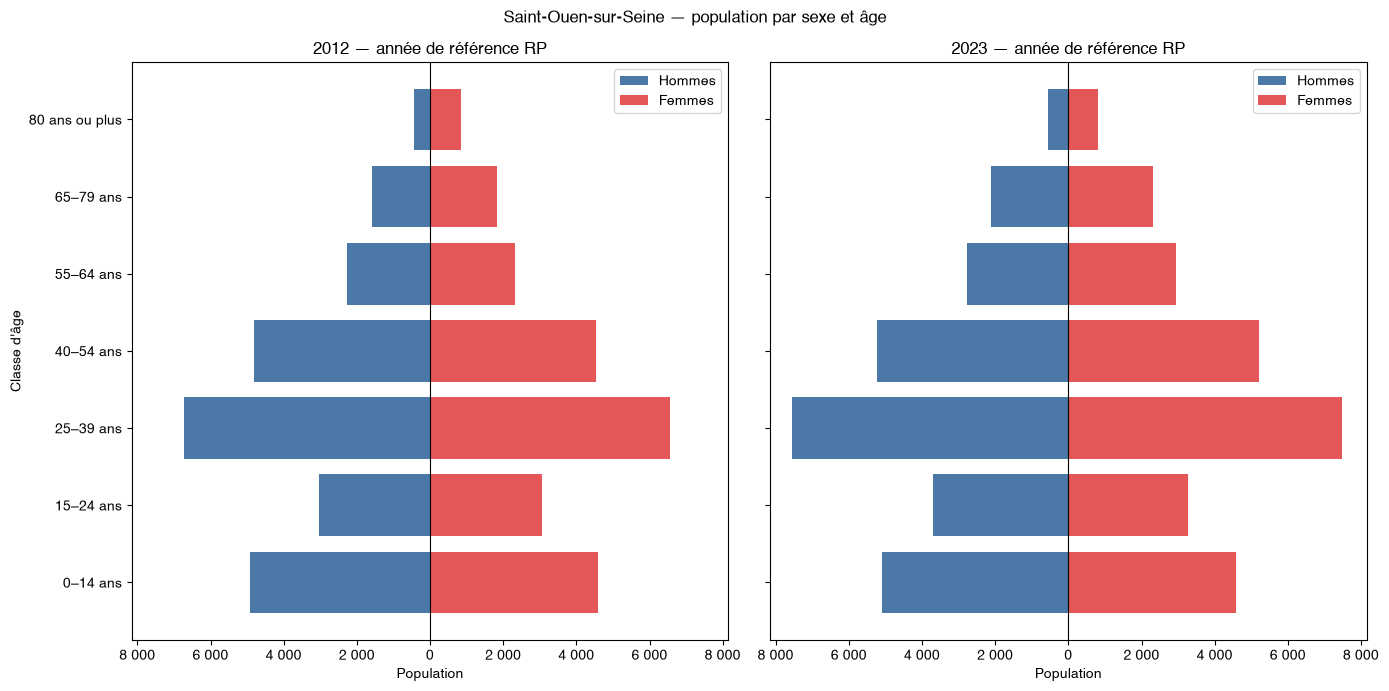

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)

maximum = pyramide_population[["femmes", "hommes"]].to_numpy().max() * 1.08

for ax, annee in zip(axes, sorted(pyramide_population["annee"].unique())):
    donnees_annee = pyramide_population.loc[
        pyramide_population["annee"] == annee
    ]

    ax.barh(
        donnees_annee["classe_age"],
        -donnees_annee["hommes"],
        color="#4C78A8",
        label="Hommes",
    )
    ax.barh(
        donnees_annee["classe_age"],
        donnees_annee["femmes"],
        color="#E45756",
        label="Femmes",
    )

    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlim(-maximum, maximum)
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda valeur, _: f"{abs(valeur):,.0f}".replace(",", " "))
    )
    ax.set_title(f"{annee} — année de référence RP")
    ax.set_xlabel("Population")
    ax.legend()

axes[0].set_ylabel("Classe d'âge")
fig.suptitle("Saint-Ouen-sur-Seine — population par sexe et âge")
fig.tight_layout()
plt.show()

La comparaison des pyramides des âges de Saint-Ouen-sur-Seine entre 2012 et 2023 suggère une progression marquée des classes d’âge actif.


- On constate une structure « en toupie » dominée par les 25–54 ans aux deux dates. La population se concentre fortement dans les classes d’âge actif. Le pic se situe chez les 25–39 ans, qui passent d’environ 6 700 hommes et 6 550 femmes en 2012 à près de 7 500 hommes et 7 450 femmes en 2023 (soit près de 15 000 habitants dans cette seule tranche), suivis par les 40–54 ans (autour de 5 150 hommes et 5 200 femmes en 2023).
- On remarque en effet une croissance plus marquée chez les adultes d’âge actif. Entre 2012 et 2023, l’élargissement de la pyramide repose essentiellement sur la progression des 25–39 ans (+800 à +900 personnes par sexe), des 40–54 ans (+350 à +700) et des 55–64 ans (+500 à +650). À l’inverse, la base des 0–14 ans reste quasi stable (environ 5 000 garçons et 4 600 filles), et le creux des 15–24 ans (3 650 hommes et 3 300 femmes en 2023) demeure prononcé.
- Enfin, on observe un vieillissement contenu et un déséquilibre hommes-femmes aux grands âges. Les 65–79 ans progressent modérément (d’environ 1 600–1 800 par sexe en 2012 à 2 100–2 350 en 2023), tandis que le sommet des 80 ans ou plus reste étroit (environ 500 hommes et 850 à 900 femmes). La répartition par sexe est globalement équilibrée jusqu’à 54 ans, puis devient plus féminine à partir de 55 ans.


Cette progression des classes d’âge actif invite à examiner, dans la section suivante, l’évolution du profil socio-économique des quartiers.

III - Profil socio-éco

IV - Logements et transactions

B- Ligne 14 et données immobilières 

On s'est demandé si l'arrivée de la ligne 14 n'aurait pas été à l'origine d'une hausse de l'immobilier. On charge les stations proches de la zone d'étude avec un helper de utils.py, puis on définit un seuil de 500m, qui est une distance en dessous laquelle on peut considérer qu'un logement est proche de la ligne 14. 

In [11]:
stations_proches = utils.charger_stations_proches(zone_etude)

On compare ensuite les mutations immobilières selon leur proximité réelle avec une station de métro.

Elle écarte d’abord les mutations sans coordonnées (année ou prix au m²) puis projette les points des ventes et les stations en EPSG:2154 afin de calculer des distances en mètres. Chaque mutation est affectée à la station la plus proche et classée dans l’un des deux groupes : à moins de 500 m ou à 500 m et plus. 

Enfin, on calcule, pour chaque année et chaque groupe, le prix médian au m² et le nombre de mutations, puis affiche ces deux tableaux. 

In [ ]:
DISTANCE_SEUIL_M = 500

df_analyse = df_logements.dropna(
    subset=["longitude", "latitude", "annee", "prix_m2"]
).copy()

ventes_geo = gpd.GeoDataFrame(
    df_analyse,
    geometry=gpd.points_from_xy(df_analyse["longitude"], df_analyse["latitude"]),
    crs="EPSG:4326",
).to_crs("EPSG:2154")

stations_geo = stations_proches.to_crs("EPSG:2154")

df_analyse["dist_station_m"] = ventes_geo.geometry.apply(
    lambda point: stations_geo.geometry.distance(point).min()
).to_numpy()

groupe_proche = "Zone Traitée (< 500m)"
groupe_eloigne = "Zone Contrôle (≥ 500m)"

df_analyse["groupe"] = groupe_eloigne
df_analyse.loc[df_analyse["dist_station_m"] < DISTANCE_SEUIL_M, "groupe"] = groupe_proche

ordre_groupes = [groupe_proche, groupe_eloigne]

table_prix = (
    df_analyse.groupby(["annee", "groupe"])["prix_m2"]
    .median()
    .unstack()
    .reindex(columns=ordre_groupes)
)

table_effectifs = (
    df_analyse.groupby(["annee", "groupe"])["prix_m2"]
    .count()
    .unstack()
    .reindex(columns=ordre_groupes)
)

print("Prix médian au m² (€) par proximité réelle d'une station")
display(table_prix.round(0))

print("Nombre de mutations par année et groupe")
display(table_effectifs)

Prix médian au m² (€) par proximité réelle d'une station


groupe,Zone Traitée (< 500m),Zone Contrôle (≥ 500m)
annee,,
2018,5276.0,5278.0
2019,6000.0,5742.0
2020,6221.0,6265.0
2021,6857.0,6654.0
2022,7004.0,6897.0
2023,6767.0,6655.0
2024,6384.0,6220.0
2025,6500.0,6349.0


Nombre de mutations par année et groupe


groupe,Zone Traitée (< 500m),Zone Contrôle (≥ 500m)
annee,,
2018,222,503
2019,398,424
2020,329,447
2021,393,556
2022,356,561
2023,264,383
2024,226,352
2025,260,466


On appelle ensuite `calculer_zones_tampons` pour mesurer la proximité des IRIS de la zone d’étude par rapport aux stations.

La fonction projette les IRIS et les stations en Lambert-93 (`EPSG:2154`), un système adapté aux calculs de distances en mètres. Pour chaque IRIS, elle mesure la distance entre son centroïde et la station la plus proche, puis le classe en zone traitée ou zone de contrôle selon le seuil indiqué par `DISTANCE_SEUIL_M`.

Elle construit également deux zones tampons autour des stations : `buffer_traite`, au rayon du seuil choisi (500 m ici), et `buffer_etendu`, au rayon par défaut de 800 m. Les trois résultats sont renvoyés dans le système de coordonnées d’origine.

- `iris_classes` contient les IRIS, leur distance à la station la plus proche et leur groupe.
- `buffer_traite` et `buffer_etendu` sont les zones tampons, utiles notamment pour les visualisations cartographiques.

**Attention :** la distance est calculée depuis le centroïde de chaque IRIS, pas depuis chaque logement vendu. De plus, la condition du code classe une distance exactement égale au seuil comme « traitée » (`<=`), même si l’étiquette affiche « < 500 m ».

In [14]:
iris_classes, buffer_traite, buffer_etendu = utils.calculer_zones_tampons(
    zone_etude,
    stations_proches,
    dist_traitee=DISTANCE_SEUIL_M,
)

On définit puis exécute ensuite la fonction `analyser_evolution_prix_par_distance`. Elle vérifie la présence des colonnes nécessaires, associe chaque vente à son IRIS et au groupe de proximité de cet IRIS, puis écarte les ventes dont l’année ou le prix au m² est manquant. Elle calcule ensuite, pour chaque année et chaque groupe, le prix médian au m² et le nombre de ventes.

Les groupes sont attribués aux IRIS selon leur distance aux stations; les ventes héritent donc du groupe de leur IRIS. La fonction renvoie les données associées et les deux tableaux récapitulatifs.

In [15]:
def analyser_evolution_prix_par_distance(df_ventes, iris_classes):
    """Calcule médianes et effectifs annuels par groupe de distance."""
    colonnes_requises = {utils.COL_IRIS, "annee", "prix_m2"}
    colonnes_absentes = colonnes_requises - set(df_ventes.columns)
    if colonnes_absentes:
        raise ValueError(
            f"Colonnes de ventes absentes pour l'analyse : {sorted(colonnes_absentes)}"
        )

    groupes_iris = iris_classes[
        [utils.COL_IRIS, "groupe", "dist_station_m"]
    ].copy()
    ventes = df_ventes.copy()
    ventes[utils.COL_IRIS] = ventes[utils.COL_IRIS].astype("string")
    groupes_iris[utils.COL_IRIS] = groupes_iris[utils.COL_IRIS].astype("string")
    df_analyse = ventes.merge(
        groupes_iris,
        on=utils.COL_IRIS,
        how="inner",
        validate="many_to_one",
    ).dropna(subset=["annee", "prix_m2"])
    if df_analyse.empty:
        raise ValueError("Aucune vente exploitable n'est associée à un IRIS classé.")

    table_prix = (
        df_analyse.groupby(["annee", "groupe"])["prix_m2"]
        .median()
        .unstack()
    )
    table_effectifs = (
        df_analyse.groupby(["annee", "groupe"])["prix_m2"]
        .count()
        .unstack()
    )
    return df_analyse, table_prix, table_effectifs


df_analyse, table_prix, table_effectifs = analyser_evolution_prix_par_distance(
    df_logements,
    iris_classes,
)

La seconde cellule trace l’évolution annuelle du prix médian au m² pour chaque groupe. Les couleurs et les marqueurs distinguent les groupes, tandis que la ligne verticale pointillée situe la mise en service de la ligne 14 en décembre 2020. La mise en forme de l’axe des prix, la grille et la légende facilitent la lecture du graphique.

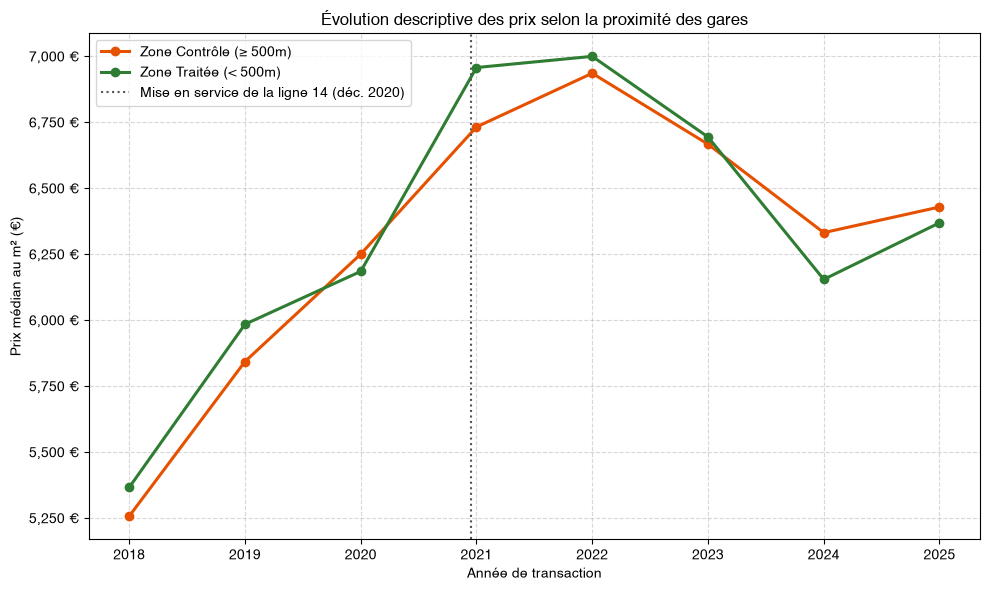

In [16]:
fig, ax = plt.subplots(figsize=(10, 6))
couleurs = ["#e65100", "#2e7d32"]

for couleur, groupe in zip(couleurs, table_prix.columns):
    ax.plot(
        table_prix.index,
        table_prix[groupe],
        marker="o",
        linewidth=2.2,
        color=couleur,
        label=groupe,
    )

ax.axvline(
    x=2020.95,
    color="#555555",
    linestyle=":",
    linewidth=1.5,
    label="Mise en service de la ligne 14 (déc. 2020)",
)
ax.set_title("Évolution descriptive des prix selon la proximité des gares")
ax.set_xlabel("Année de transaction")
ax.set_ylabel("Prix médian au m² (€)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f} €"))
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()


En 2018, les prix médians au m² sont presque identiques dans les deux zones : 5 276 € à moins de 500 mètres d’une station, contre 5 278 € au-delà. Les prix augmentent ensuite dans les deux groupes jusqu’en 2022, où ils atteignent leur niveau le plus élevé : 7 004 € dans la zone proche et 6 897 € dans la zone de contrôle. Ils baissent ensuite jusqu’en 2024, avant de remonter légèrement en 2025.

À partir de 2021, le prix médian est chaque année plus élevé dans la zone proche des stations. L’écart reste toutefois modéré : entre 107 € et 203 €/m², soit environ 1,6 % à 3,1 % par rapport à la zone de contrôle. Les évolutions des deux groupes restent globalement similaires.

Ces résultats sont descriptifs et ne suffisent pas à conclure que la proximité d’une station entraîne une hausse des prix ou révèle, à elle seule, un phénomène de gentrification. Les effectifs de ventes diffèrent entre les groupes et varient selon les années — de 222 à 398 mutations dans la zone proche, contre 352 à 561 dans la zone de contrôle. Les différences observées peuvent aussi refléter la composition des logements vendus ou les caractéristiques des quartiers. Une analyse causale nécessiterait notamment de contrôler ces facteurs et de comparer les évolutions avant et après la mise en service des stations.